In [1]:
# Setting system path and project root
import os
import sys

PROJECT_ROOT_DIR = os.path.abspath('../../../')
sys.path.append(PROJECT_ROOT_DIR) # bringing system path to project root

In [2]:
import pandas as pd

csv_path = os.path.join(PROJECT_ROOT_DIR, "data_dir/fineweb2_metadata/fineweb2-language-distribution.csv")
fw2_lang_doc_distr_df = pd.read_csv(csv_path)

# Remove rows where the "subset" column ends with "_removed"
mask = (
    ~fw2_lang_doc_distr_df["subset"].astype(str).str.endswith("_removed") &
    (fw2_lang_doc_distr_df["split"] == "train")
)
fw2_lang_doc_distr_df = fw2_lang_doc_distr_df.loc[mask].reset_index(drop=True)

print(f'Shape of fw2 dataframe after filtering values: {fw2_lang_doc_distr_df.shape}')

columns_of_interest = ["code", "name", "script", "family"]

for col in columns_of_interest:
    if col in fw2_lang_doc_distr_df.columns:
        uniques = fw2_lang_doc_distr_df[col].dropna().unique()   # drop NaN, then get uniques
        print(f"\nUnique values in '{col}' ({len(uniques)} total):")
        # print(uniques)
    else:
        print(f"\nColumn '{col}' not found in the CSV.")

Shape of fw2 dataframe after filtering values: (1911, 14)

Unique values in 'code' (1812 total):

Unique values in 'name' (1811 total):

Unique values in 'script' (59 total):

Unique values in 'family' (103 total):


In [3]:
# Joel: took 190 languages, referred to the languages that can be evaluated (through lm-eval-harness)
# Rene: Can refer to the last shared paper on how they managed the split

In [4]:
## Obsolete: Not the best way to cluster languages, better to rely on pre-clustered data
# from sklearn.preprocessing import StandardScaler
# from sklearn.cluster import KMeans

# docs_vals = fw2_lang_dist_df[["documents"]].astype(float)

# scaler = StandardScaler()
# docs_scaled = scaler.fit_transform(docs_vals)

# n_val = 100

# kmeans = KMeans(
#     n_clusters=n_val,
#     init="k-means++",
#     n_init='auto',
#     random_state=42
# )
# fw2_lang_dist_df["lang_group"] = kmeans.fit_predict(docs_scaled)

# centroid_vals = scaler.inverse_transform(kmeans.cluster_centers_).flatten()
# label_names = [f"Group_{i}" for i in range(n_val)]          # generic names
# sorted_idx = centroid_vals.argsort()
# label_map = {sorted_idx[i]: label_names[i] for i in range(n_val)}

# fw2_lang_dist_df["lang_group"] = fw2_lang_dist_df["lang_group"].map(label_map)

# print("\nLanguages have been clustered into groups based on 'documents':")
# print(fw2_lang_dist_df[["name", "documents", "lang_group"]].head())

In [5]:
import pandas as pd

csv_path = os.path.join(PROJECT_ROOT_DIR, "data_dir/fineweb2_metadata/lang_resource_dataset.tsv")
lang_resource_df = pd.read_csv(csv_path, sep="\t")

columns_of_interest = ["lang_code", "resource_category"]

for col in columns_of_interest:
    if col in lang_resource_df.columns:
        uniques = lang_resource_df[col].dropna().unique()   # drop NaN, then get uniques
        print(f"\nUnique values in '{col}' ({len(uniques)} total):")
        print(uniques)
    else:
        print(f"\nColumn '{col}' not found in the CSV.")


Unique values in 'lang_code' (1572 total):
['bul_cyrl' 'zho_hans' 'ces_latn' ... 'tmw_latn' 'toi_latn' 'hsn_hans']

Unique values in 'resource_category' (6 total):
['high' 'medhigh' 'medlow*' 'medlow' 'low' 'not_enough']


In [6]:
# Match all the rows from fw2_lang_dist_df where "subset" has same value as "lang_code" of lang_resource_df when compared in lowercase
# For each matched row from fw2_lang_dist_df, map the "subset" value against "resource_category" from lang_resource_df

# Drop rows where the mapped resource_category ends with "*"
lang_resource_df = lang_resource_df[
    ~lang_resource_df['resource_category'].str.endswith('*', na=False)
]

# Normalize the keys to lower‑case for a case‑insensitive join
fw2_lang_doc_distr_df['_subset_lc'] = fw2_lang_doc_distr_df['subset'].astype(str).str.lower()
lang_resource_df['_lang_code_lc'] = lang_resource_df['lang_code'].astype(str).str.lower()


# Perform a left join to keep all rows from the fineweb2 dataframe
fw2_lang_doc_distr_df = fw2_lang_doc_distr_df.merge(
    lang_resource_df[['_lang_code_lc', 'resource_category']],
    left_on='_subset_lc',
    right_on='_lang_code_lc',
    how='left'
)

print(f'Shape of fw2 dataframe after merging: {fw2_lang_doc_distr_df.shape}')

# Clean‑up helper columns
fw2_lang_doc_distr_df.drop(columns=['_subset_lc', '_lang_code_lc'], inplace=True)

# Preview the result
#print("\nSample rows with mapped resource categories:")
#print(fw2_lang_doc_distr_df[['subset', 'resource_category']].head())

Shape of fw2 dataframe after merging: (1911, 17)


In [7]:
# Sort fw2_lang_dist_df by "documents" descending & find last row index for each unique value "resource_category"

fw2_lang_doc_distr_df = fw2_lang_doc_distr_df.sort_values(
    by="documents",
    ascending=False
).reset_index(drop=True)

#print("\nDataframe sorted by 'documents' (desc):")
#print(fw2_lang_doc_distr_df[["subset", "documents", "resource_category"]].head())

# Group by `resource_category` and grab the index of the last entry in each group
last_idx_series = fw2_lang_doc_distr_df.groupby("resource_category").apply(
    lambda grp: grp.index[-1]  # last row of the sorted group
)

# Convert to a plain dict for easy lookup
last_idx_by_category = last_idx_series.to_dict()

res_cat_tuples = []
#print("\nLast row index for each `resource_category`:")
for cat, idx in last_idx_by_category.items():
    #print(f"{cat!r}: {idx}")
    res_cat_tuples.append((cat, idx))

/tmp/ipykernel_847244/3698928166.py:12: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  last_idx_series = fw2_lang_doc_distr_df.groupby("resource_category").apply(


In [8]:
res_cat_tuples.sort(key=lambda tup: tup[1])
print(f'Initial categories: {res_cat_tuples}') # from the reference tsv

Initial categories: [('high', 32), ('medhigh', 60), ('medlow', 690), ('low', 1550), ('not_enough', 1899)]


In [9]:
# Manually merge categories and convert to three: high, medium, low
from enum import Enum

class Category(str, Enum):
    HIGH   = "high"
    MEDIUM = "medium"
    LOW    = "low"

# Map the original labels to the new enum members
MERGE_MAP = {
    "high"      : Category.HIGH,
    "medhigh"   : Category.MEDIUM,
    "medlow"    : Category.LOW,
    "low"       : Category.LOW,
    "not_enough": Category.LOW,
}

res_cat_tuples = [(MERGE_MAP[item[0]].value, item[1]) for item in res_cat_tuples]
print(f'Merged categories: {res_cat_tuples}')

Merged categories: [('high', 32), ('medium', 60), ('low', 690), ('low', 1550), ('low', 1899)]


In [10]:
# For each item in res_cat_tuples set the "resource_category" in fw2_lang_dist_df for all rows until item[1] to the value of item[0], set item[1] as start point for the next iteration
prev_end = 0  # start of the current slice (inclusive)
for cat, end_idx in res_cat_tuples:
    # Assign the category to all rows from `prev_end` up to `end_idx` (inclusive)
    fw2_lang_doc_distr_df.loc[prev_end:end_idx, "resource_category"] = cat
    # Next slice starts after the current end index
    prev_end = end_idx + 1

# If there are rows after the last recorded index, forward‑fill them
if prev_end < len(fw2_lang_doc_distr_df):
    fw2_lang_doc_distr_df.loc[prev_end:, "resource_category"] = fw2_lang_doc_distr_df["resource_category"].ffill()

# Quick sanity check
#print("\nAfter propagating `resource_category`:")
#print(fw2_lang_doc_distr_df[["subset", "resource_category"]].head(20))

In [11]:
# TODO: Create some visualizations to show distribution of resource_category, script and family in fw2_lang_doc_distr_df

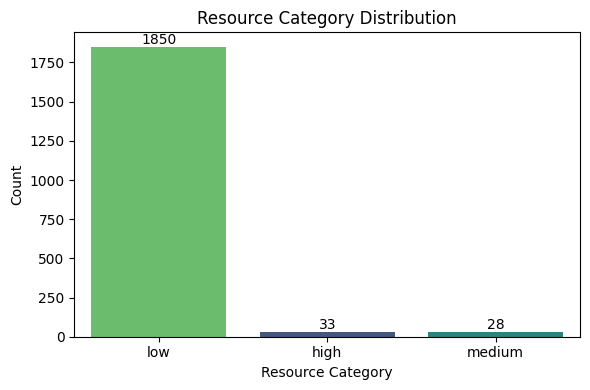

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(6,4))
ax = sns.countplot(
    data=fw2_lang_doc_distr_df,
    x="resource_category",
    hue="resource_category",
    order=fw2_lang_doc_distr_df["resource_category"]
          .value_counts()
          .index,
    palette="viridis",
    legend=False
)
plt.title("Resource Category Distribution")
plt.ylabel("Count")
plt.xlabel("Resource Category")
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge')   # shows the count in front of each bar
plt.tight_layout()
plt.show()

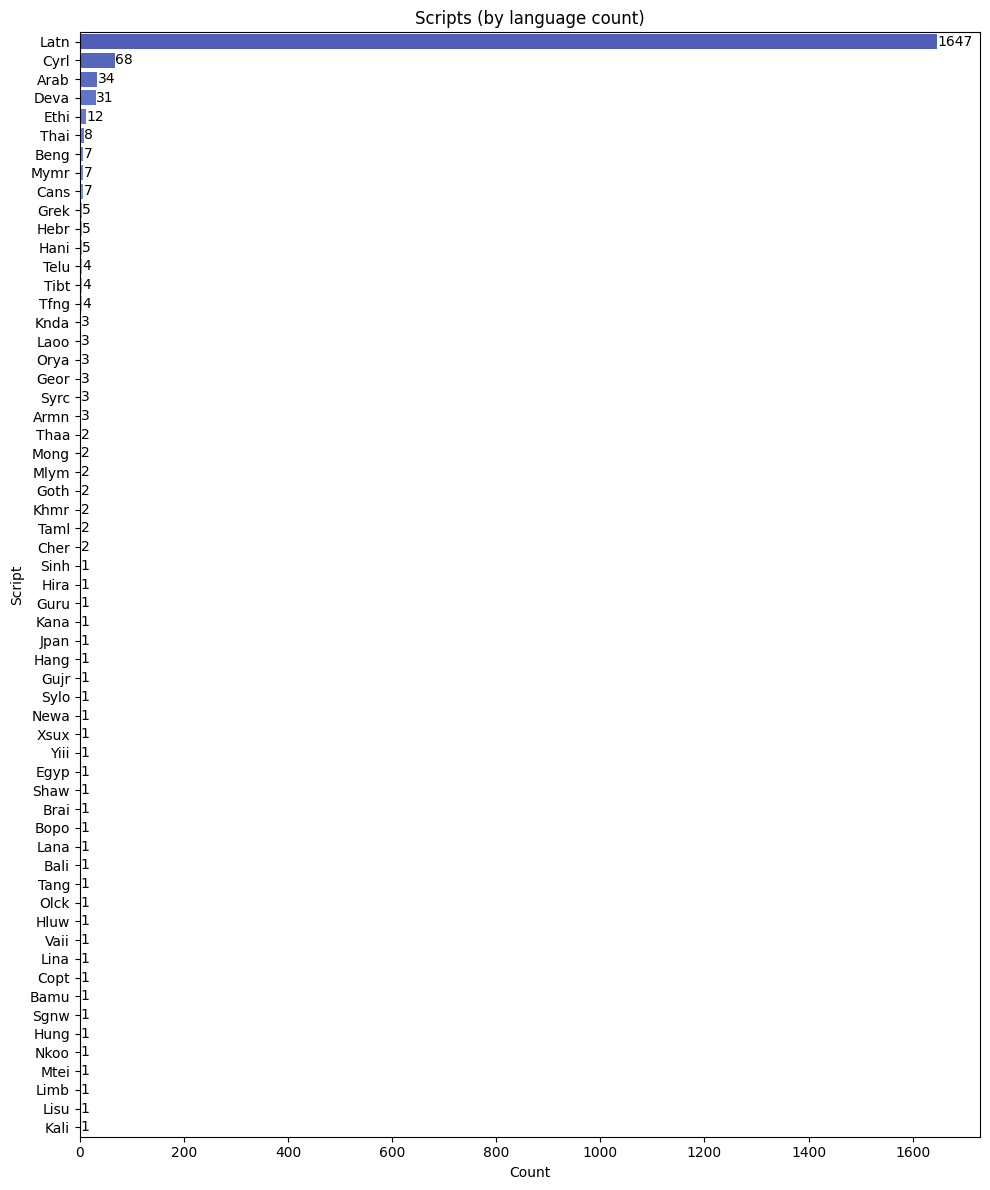

In [13]:
plt.figure(figsize=(10,12))
script_counts = fw2_lang_doc_distr_df["script"].value_counts()#.head(20) # choose head for top-n values
ax = sns.barplot(
    x=script_counts.values,
    y=script_counts.index,
    hue=script_counts.index,
    palette="coolwarm",
    legend=False
)
plt.title("Scripts (by language count)")
plt.xlabel("Count")
plt.ylabel("Script")
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge')
plt.tight_layout()
plt.show()


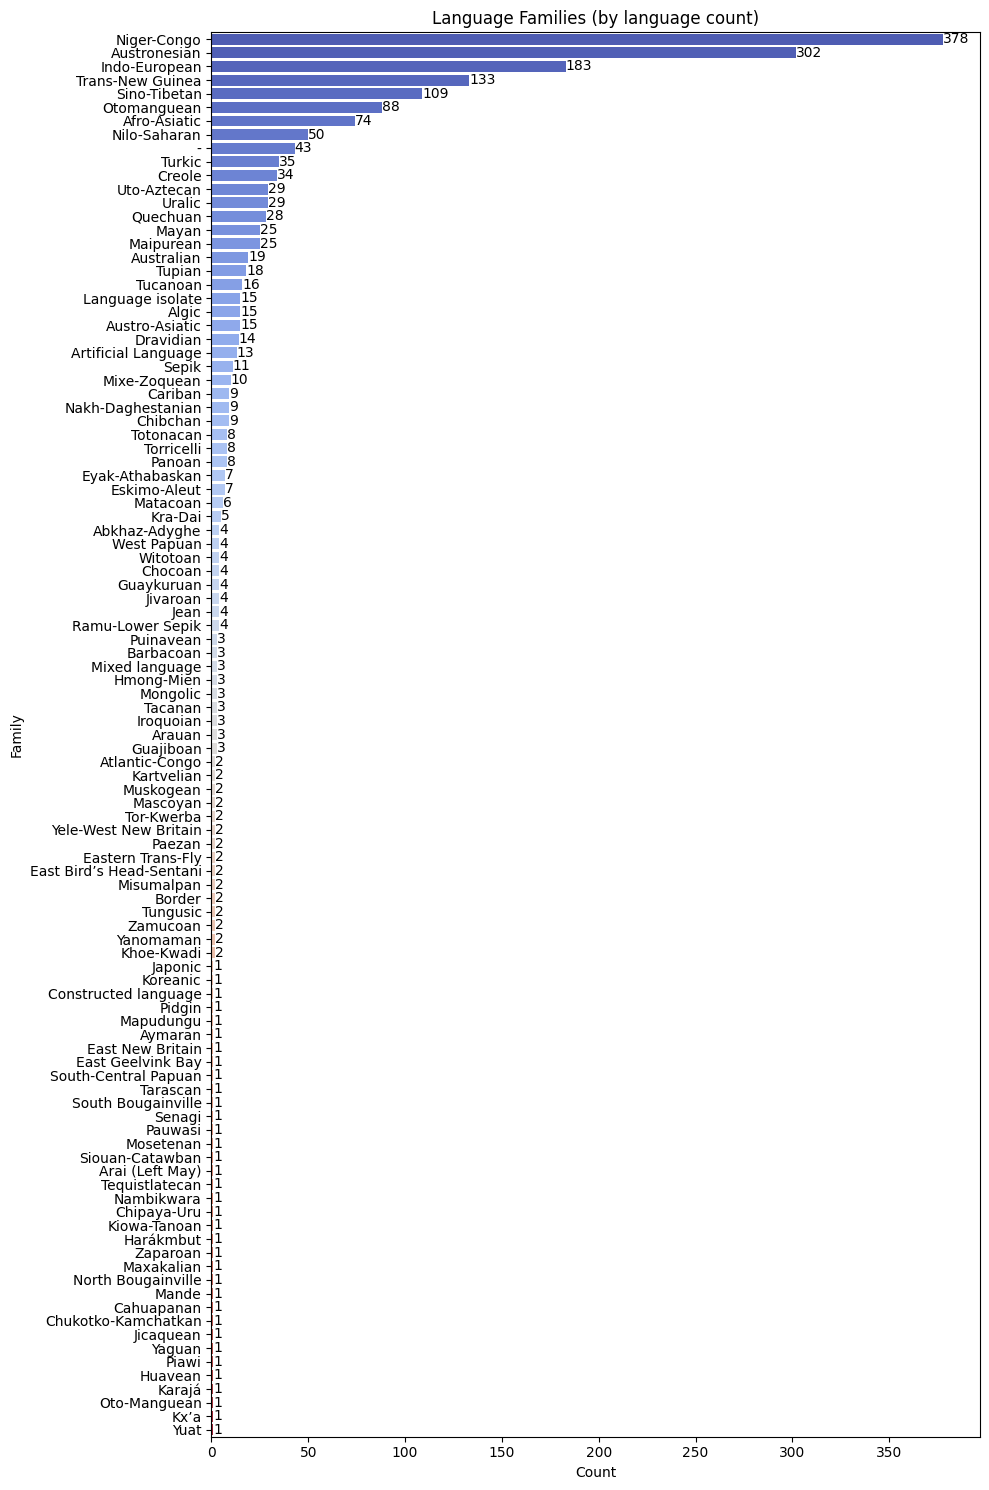

In [14]:
plt.figure(figsize=(10,15))
family_counts = fw2_lang_doc_distr_df["family"].value_counts()#.head(20) # choose head for top-n values
ax = sns.barplot(
    x=family_counts.values,
    y=family_counts.index,
    hue=family_counts.index,
    palette="coolwarm",
    legend=False
)
plt.title("Language Families (by language count)")
plt.xlabel("Count")
plt.ylabel("Family")
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge')
plt.tight_layout()
plt.show()

In [15]:
# Show representation of resource_category, script and family through a single visualization?
# Create a hierarchical visualization using treemap
import plotly.express as px

# Prepare aggregated data for visualization
agg_data = fw2_lang_doc_distr_df.groupby(['family', 'script', 'resource_category']).size().reset_index(name='count')

# Create treemap visualization
fig = px.treemap(
    agg_data,
    path=['family', 'script', 'resource_category'],
    values='count',
    color='resource_category',
    color_discrete_map={
        'high': '#2ca02c',      # Green
        'medium': '#ff7f0e',    # Orange
        'low': '#d62728'        # Red
    },
    title='Language Distribution by Family, Script, and Resource Category',
    width=1200,
    height=800
)

# Update layout for better readability
fig.update_traces(
    textinfo='label+percent parent',
    texttemplate='%{label}<br>%{value} (%{percentParent:.1%})'
)
fig.update_layout(
    margin=dict(t=50, l=25, r=25, b=25)
)

# Show the plot
fig.show()

# Alternative: Create a sunburst plot for radial visualization
fig_sunburst = px.sunburst(
    agg_data,
    path=['family', 'script', 'resource_category'],
    values='count',
    color='resource_category',
    color_discrete_map={
        'high': '#2ca02c',
        'medium': '#ff7f0e',
        'low': '#d62728'
    },
    title='Hierarchical Language Distribution',
    width=1000,
    height=1000
)

fig_sunburst.update_layout(margin=dict(t=50, l=0, r=0, b=0))
fig_sunburst.show()


In [16]:
# Create one-hot vector of length 3 (resource_cat) + 59 (script) + 103 (language_family) = 165 for each language

# Define the mapping for the resource category
resource_cat_onehot = pd.get_dummies(
    fw2_lang_doc_distr_df["resource_category"], 
    prefix="rc"
)

# One‑hot for script (59 possible values) – column name is assumed to be "script"
script_onehot = pd.get_dummies(
    fw2_lang_doc_distr_df["script"], 
    prefix="script"
)

# One‑hot for language family (103 possible values) – column name is assumed to be "family"
family_onehot = pd.get_dummies(
    fw2_lang_doc_distr_df["family"], 
    prefix="family"
)

# Concatenate all one‑hot vectors → final feature matrix (165 columns)
features_df = pd.concat(
    [resource_cat_onehot, script_onehot, family_onehot], 
    axis=1
)

print("\nOne‑hot feature shape:", features_df.shape)   # should be (n_lang, 165)


One‑hot feature shape: (1911, 165)


In [17]:
# features_df

In [18]:
uniques = fw2_lang_doc_distr_df['family'].dropna().unique() 
len(uniques)

103

In [19]:
# Cluster the languages into SAMPLE_SIZE clusters and then take the medoid (most central point) of each cluster as your representative
from sklearn.cluster import KMeans
import numpy as np
from sklearn.metrics import pairwise_distances

SAMPLE_SIZE = 200

kmeans = KMeans(
    n_clusters=SAMPLE_SIZE,
    init="k-means++",
    n_init='auto',
    random_state=42
)
cluster_labels = kmeans.fit_predict(features_df)

fw2_lang_doc_distr_df["cluster_id"] = cluster_labels

# Convert the one‑hot DataFrame to a NumPy array for fast distance computation
X = features_df.values
distance_matrix = pairwise_distances(X, metric="euclidean")

medoid_indices = []   # will store the original dataframe index of each medoid

for clust_id in range(SAMPLE_SIZE):
    # indices of rows belonging to the current cluster
    member_mask = (cluster_labels == clust_id)
    member_idxs = np.where(member_mask)[0]

    # slice the distance matrix to only those members
    sub_dm = distance_matrix[np.ix_(member_idxs, member_idxs)]

    # sum distances for each member and pick the smallest
    medoid_rel_idx = np.argmin(sub_dm.sum(axis=1))
    medoid_abs_idx = member_idxs[medoid_rel_idx]

    medoid_indices.append(medoid_abs_idx)

representative_df = fw2_lang_doc_distr_df.iloc[medoid_indices].reset_index(drop=True)

print("\nRepresentative languages (medoids) computed")


Representative languages (medoids) computed


In [20]:
representative_df.to_csv(os.path.join(PROJECT_ROOT_DIR, f"data_dir/fineweb2_metadata/{SAMPLE_SIZE}_representative_mediods.csv"), index=False)

In [21]:
representative_df[["name", "resource_category", "script", "family", "cluster_id"]]

,name,resource_category,script,family,cluster_id
0,Narom,low,Latn,Austronesian,0
1,Swahili (individual language),low,Latn,Niger-Congo,1
2,Lushai,low,Latn,Sino-Tibetan,2
3,Latin,low,Latn,Indo-European,3
4,Telefol,low,Latn,Trans-New Guinea,4
...,...,...,...,...,...
195,Hiri Motu,low,Latn,Pidgin,195
196,Otomian languages,low,Latn,Oto-Manguean,196
197,Undetermined language,low,Newa,-,197
198,Undetermined language,low,Cher,-,198
